# Quadratic Modeling

In [33]:
import os
import joblib
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

plt.style.use("dark_background")

## Import and Prepare Data

**Select either  `removal` or `recovery` as the desired Output here!**

After selecting the desired output, the required data is imported. For simplicity, the features (*Flow_C*, *Flow_P*, and *Current_Limit_P*) are always imported from the cache folder here, which saves having to convert them to the correct format from the CSV files. Depending on which output variable you selected previously, either the data for the output variable *Average Salt Removal* or *Average Water Recovery* is loaded.

In [34]:
output = "removal"

In [35]:
cached_objects_prepared_data_path = os.path.join(
    os.path.dirname(os.getcwd()), "..", "cached_objects", "prepared_data"
)

X = joblib.load(os.path.join(cached_objects_prepared_data_path, "X.npy"))

if output == "removal":
    y = joblib.load(
        os.path.join(cached_objects_prepared_data_path, "y_removal.npy")
    ).reshape(-1, 1)
    y_label = joblib.load(
        os.path.join(cached_objects_prepared_data_path, "y_label_removal.npy")
    )
    y_name = "removal"
elif output == "recovery":
    y = joblib.load(
        os.path.join(cached_objects_prepared_data_path, "y_recovery.npy")
    ).reshape(-1, 1)
    y_label = joblib.load(
        os.path.join(cached_objects_prepared_data_path, "y_label_recovery.npy")
    )
    y_name = "recovery"

## Quadratic Model

Looking at the data points from the data preperation Jupyter Notebook, it quickly becomes apparent that the relationship between input and output variables cannot be mapped linearly, as there are several local minimum and maximum values. If you want to use conventional modeling methods such as linear regression, you must therefore map the non-linear relationships between the features in advance. A polynomial of a higher degree than degree two would probably lead to severe overfitting given the limited amount of data available and is therefore not considered.

Instead, a *PolynomialFeatures* object is created here to formulate a quadratic term from the three input variables, whose coefficients can then be calculated in the next step using linear regression.
- *degree* is used to specify the degree of the polynomial to be created.
- *interaction_only* can be set to *true* if you are only interested in terms that represent the correlation between features.
- *include_bias* can be used to specifically exclude the constant term *1*.
- The function *get_feature_names_out* returns all formulated terms so that they can be used for graphical representation or later processing.

Before applying linear regression in the next step, it makes sense to take a look at how the values of the terms are distributed across all data points. A heat map showing the distribution is useful here. For example, you can see that *x3* always occurs with a maximum value, both quadratically and non-quadratically, over the first 11 data points. This should be kept in mind when interpreting the results later.

The graph on the right, on the other hand, shows the average value of the individual terms across all data points. Only the constant value *1* stands out here, but this could be omitted when creating the quadratic terms if necessary.

At this point, it should be mentioned that there are many other possibilities for optimizing the model, for example, by deliberately omitting terms where it is certain that it does not make sense to model their dependency because there may not be any.

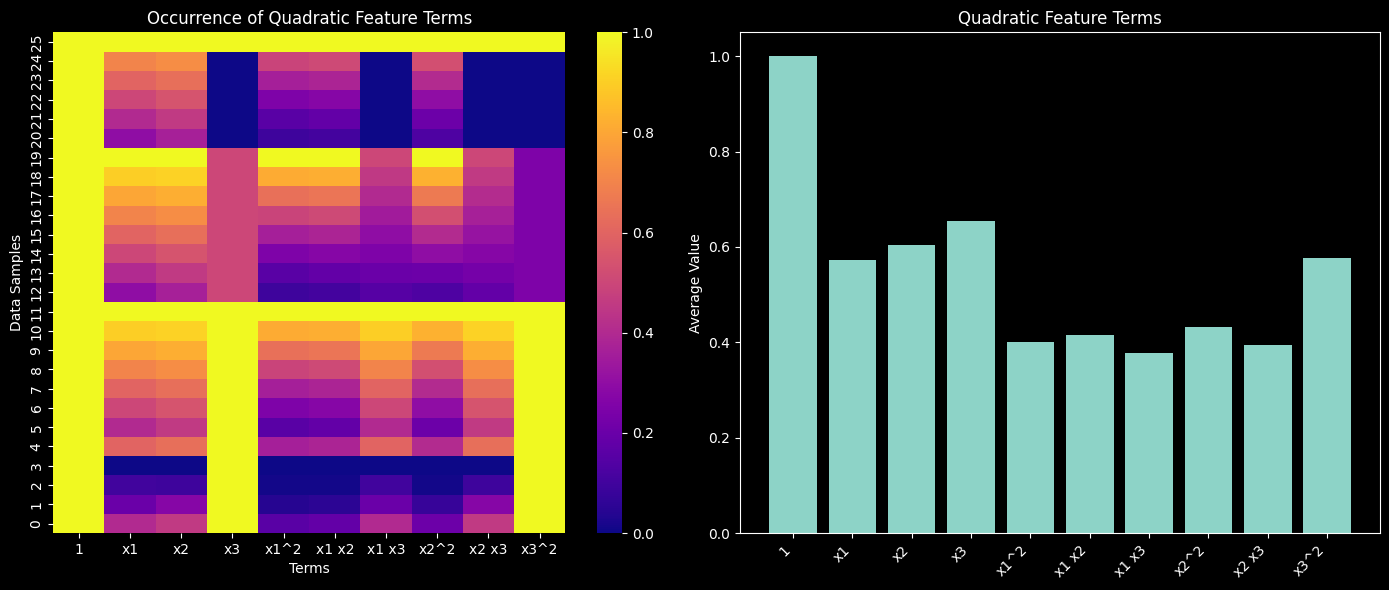

In [ ]:
# Create quadratic features
poly = PolynomialFeatures(degree=2, interaction_only=False, include_bias=True)
X_quad = poly.fit_transform(X)

# Extract quadratic terms
feature_names = poly.get_feature_names_out(["x1", "x2", "x3"])

# Create data frame for further processing
X_quad_df = pd.DataFrame(X_quad, columns=feature_names)

# Visualize quadratic features
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(X_quad_df, annot=False, ax=axes[0], cmap="plasma")
axes[0].set_title("Occurrence of Quadratic Feature Terms")
axes[0].set_xlabel("Terms")
axes[0].set_ylabel("Data Samples")
axes[0].invert_yaxis()

axes[1].bar(feature_names, np.mean(X_quad, axis=0))
axes[1].set_ylabel("Average Value")
axes[1].set_title("Quadratic Feature Terms")
axes[1].set_xticks(range(len(feature_names)))
axes[1].set_xticklabels(feature_names, rotation=45, ha="right")

plt.tight_layout()
plt.show()

## Model Fitting

Now it is time to determine the coefficients, for which we use linear regression. Linear regression automatically determines the coefficients so that the *Mean Squared Error (MSE)* is as low as possible.

In order to apply linear regression to the quadratic terms, a *LinearRegression* object is first created.
- Using *fit_intercept=True* is useful because it means that the regression line does not necessarily have to pass through the origin and can therefore fit the data better.
- *positive=True* is used to set that the input variables can have both a positive and a negative effect on the output values.

The model created is then used to make predictions based on the existing data points. These can be compared directly with the actual output values in the first graph to determine how well the model fits. The graph directly next to it shows the magnitude of the deviation for values that do not lie on the regression line.

The bottom two graphs show the resulting model. On the left are the individual results for the coefficients and on the right is the model visualized as a three dinemnsional graph. It should be noted that for better readability, one input variable (here *Current_Limit_P*) is fixed to the average value. Potential minima and maxima can already be seen in color and graphically.

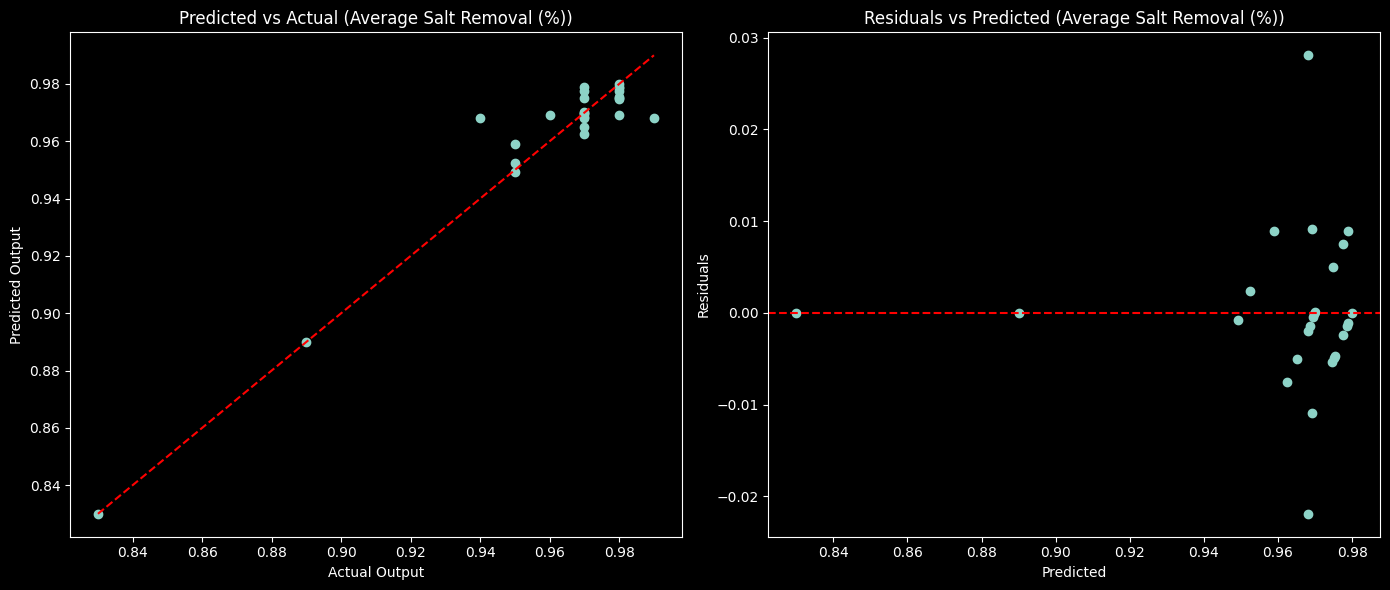

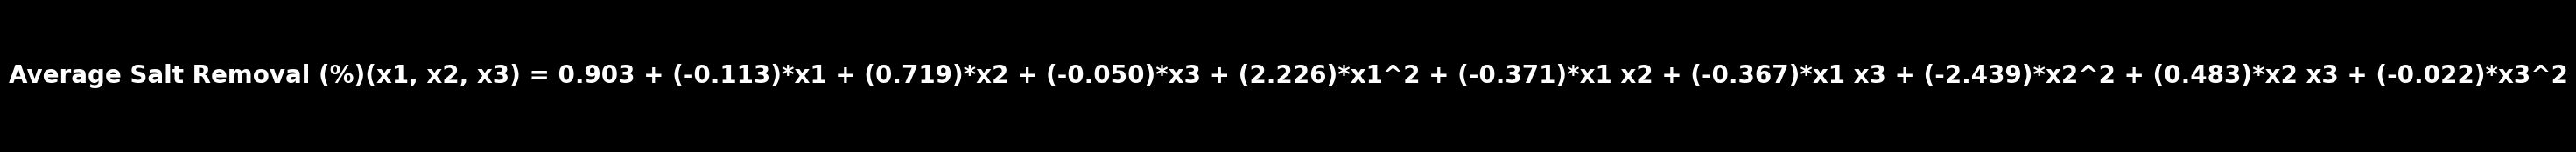

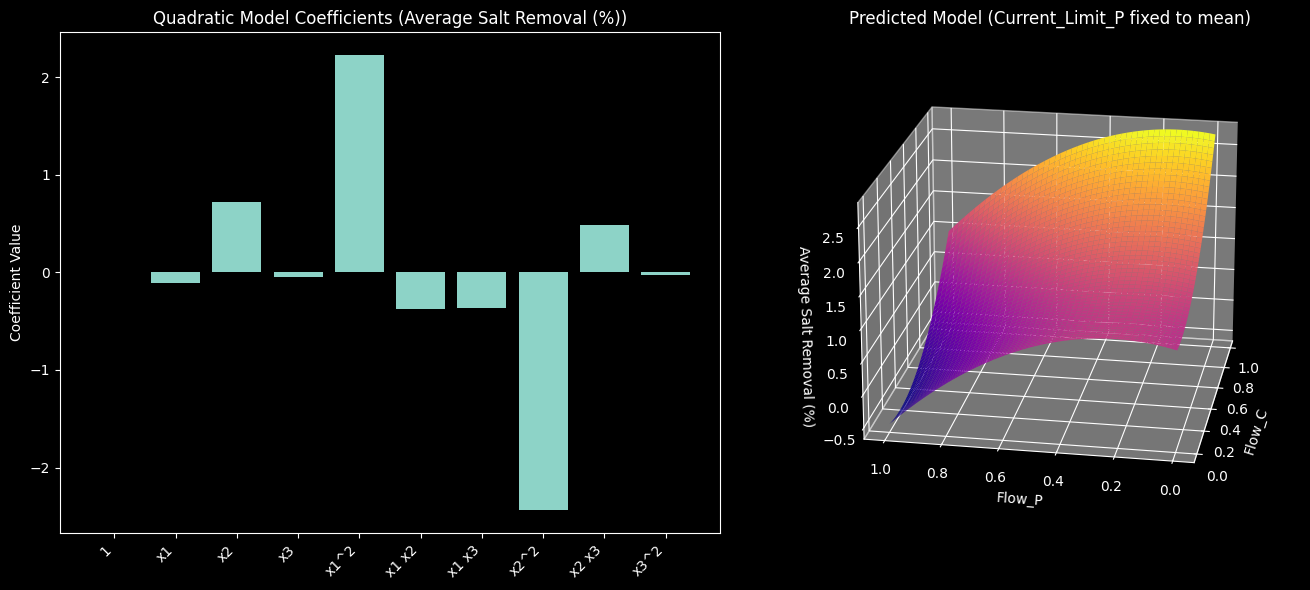

In [ ]:
# Fit linear regression model on quadratic features
model = LinearRegression(fit_intercept=True, positive=False)
model.fit(X_quad, y)

# Save model predictions
y_pred = model.predict(X_quad)

# Preparations for visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Show model fit: Predicted vs Actual
axes[0].scatter(y[:, 0], y_pred[:, 0])
# Plot a red dashed diagonal line for y=x, first min and max of x and second min and max of y
axes[0].plot([y[:, 0].min(), y[:, 0].max()], [y[:, 0].min(), y[:, 0].max()], "r--")
axes[0].set_xlabel("Actual Output")
axes[0].set_ylabel("Predicted Output")
axes[0].set_title(f"Predicted vs Actual ({y_label})")

# Residuals vs Predicted
residuals = y_pred - y
axes[1].scatter(y_pred[:, 0], residuals[:, 0])
# Draw a horizontal line at y=0
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Residuals")
axes[1].set_title(f"Residuals vs Predicted ({y_label})")

plt.tight_layout()
plt.show()

# Display model equation
eq = f"{y_label}(x1, x2, x3) = "
# get the first (and only) output
terms = [f"{model.intercept_[0]:.3f}"]
# Add each coefficient multiplied by its corresponding feature name
for coef, name in zip(model.coef_[0], feature_names):
    if name != "1":
        terms.append(f"({coef:.3f})*{name}")
# Combine all terms into the full equation
eq += " + ".join(terms)
plt.figure(figsize=(12, 2))
plt.text(0.5, 0.5, eq, fontsize=20, fontweight="bold", ha="center", va="center")
plt.axis("off")

plt.show()

# Preparations for visualization
fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1)
# Get coefficients out of the model
ax1.bar(feature_names, model.coef_[0])
ax1.set_xticks(range(len(feature_names)))
ax1.set_xticklabels(feature_names, rotation=45, ha="right")
ax1.set_ylabel("Coefficient Value")
ax1.set_title(f"Quadratic Model Coefficients ({y_label})")

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
# Generate grid of values for the first two features
x1 = np.linspace(X[:, 0].min(), X[:, 0].max(), 50)
x2 = np.linspace(X[:, 1].min(), X[:, 1].max(), 50)
x1_grid, x2_grid = np.meshgrid(x1, x2)
# Fix the third feature at its mean
x3_fixed = X[:, 2].mean()
# Combine the three input arrays into a single 2D array for prediction
X_grid = np.column_stack(
    [x1_grid.ravel(), x2_grid.ravel(), np.full_like(x1_grid.ravel(), x3_fixed)]
)
# Evaluate model for every (x1, x2) pair with x3 fixed
X_grid_quad = poly.transform(X_grid)
y_grid = model.predict(X_grid_quad).reshape(x1_grid.shape)
ax2.plot_surface(x1_grid, x2_grid, y_grid, cmap="plasma")
ax2.view_init(elev=20, azim=190)
ax2.set_xlabel("Flow_C")
ax2.set_ylabel("Flow_P")
ax2.set_zlabel(f"{y_label}")
ax2.set_title("Predicted Model (Current_Limit_P fixed to mean)")

plt.tight_layout()
plt.show()

## Model Validation: LOOCV

In order to evaluate the model even better, a detailed validation is now performed. Due to the small data set, it is not really worth performing a conventional 80/20 training/test data split, as this would further reduce the already limited number of data points. Instead, we train the model on all data points and use the *Leave-One-Out Cross-Validation (LOOCV)* method as the validation method. With LOOCV, as many runs are performed as there are data points, with the model being trained on all points except one per run. Validation takes place on only one data point per run.

### Key Metrics Analysis

First, there are a few key values that can provide insight into how well the resulting model fits:

- MSE: Shows the squared difference between predicted and true values. MSE for both output variables is relatively low, which means that the predictions are close to the actual target values.
- MAE: Essentially the same meaning as MSE, but the error is directly comparable to the scale of the output variable. But here too, the error in both outputs is small.
- R^2: The higher this value, the more data points were predicted correctly. For the *Average Salt Removal*, a value of around 0.7, as seen here, means that around 70% of the variance in all measured values is covered by the model. For the output *Average Water Recovery* it's a completely different story. Here, R^2 even has a negative value, which means that in reality, not a single point was predicted accurately.

In [ ]:
# Create Leave-One-Out object
loo = LeaveOneOut()
y_valid_true = []
y_valid_pred = []

# Loop through each sample for LOOCV
for train_idx, test_idx in loo.split(X_quad):
    X_train, X_test = X_quad[train_idx], X_quad[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    model = LinearRegression(fit_intercept=True, positive=False)
    model.fit(X_train, y_train)

    y_valid_pred.append(model.predict(X_test)[0, 0])
    y_valid_true.append(y_test[0, 0])

y_ty_valid_truerue = np.array(y_valid_true)
y_valid_pred = np.array(y_valid_pred)

# Get metrics
mse = mean_squared_error(y_valid_true, y_valid_pred)
mae = mean_absolute_error(y_valid_true, y_valid_pred)
r2 = r2_score(y_valid_true, y_valid_pred)

# Print key metrics
print("\n" + "=" * 20)
print("MSE: {:.6f}".format(mse))
print("MAE: {:.6f}".format(mae))
print("R^2 : {:.6f}".format(r2))
print("=" * 20 + "\n")


MSE: 0.000289
MAE: 0.010697
R^2 : 0.727398



## Learning Curve

The learning curve offers an additional validation option, shown here with the training MSE and LOOCV validation MSE in a graph. The training MSE indicates how high the MSE is on the data used for training, and the LOOCV validation MSE indicates how large the error is on the validation data.

Models that have been trained on a small data set, and especially with little test data compared to training data, are at high risk of overfitting. Unfortunately, if *Average Salt Removal* was selected as the output label this overfitting can also be seen in the two graphs below, as the MSE on the validation data is consistently significantly higher than the MSE on the training data. If, instead, *Average Water Recovery* is chosen as the output, the two curves are already significantly closer to each other.

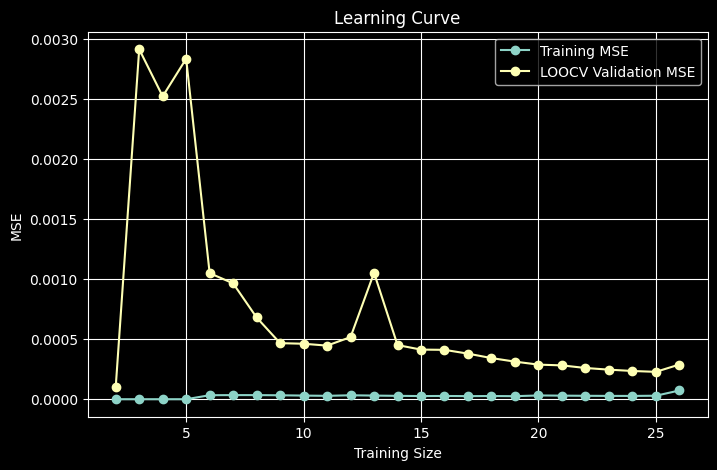

In [ ]:
# Start with 2 samples up to all samples
train_sizes = np.arange(2, len(X) + 1)
train_errors = []
val_errors = []

# Loop over all different training set sizes
for size in train_sizes:
    # Select a subset of the data for the current training size
    X_subset = X_quad[:size]
    y_subset = y[:size]

    # Compute training MSE on the current subset
    model = LinearRegression(fit_intercept=True)
    model.fit(X_subset, y_subset)
    train_mse = mean_squared_error(y_subset, model.predict(X_subset))
    train_errors.append(train_mse)

    # Compute validation MSE using Leave-One-Out Cross-Validation (LOOCV)
    loo = LeaveOneOut()
    val_mses = []
    for train_idx, test_idx in loo.split(X_subset):
        X_train, X_test = X_subset[train_idx], X_subset[test_idx]
        y_train, y_test = y_subset[train_idx], y_subset[test_idx]
        model.fit(X_train, y_train)
        val_mses.append(mean_squared_error(y_test, model.predict(X_test)))
    val_errors.append(np.mean(val_mses))

# Plot learning curve
plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_errors, "o-", label="Training MSE")
plt.plot(train_sizes, val_errors, "o-", label="LOOCV Validation MSE")
plt.xlabel("Training Size")
plt.ylabel("MSE")
plt.title("Learning Curve")
plt.grid(True)
plt.legend()
plt.show()

## Export Model

Now all relevant model parameters are exported so that they can be reused in further steps, such as optimization.

In [40]:
cached_objects_model_lin_reg_path = os.path.join(
    os.path.dirname(os.getcwd()), "..", "cached_objects", "model_lin_reg", y_name
)

joblib.dump(model, os.path.join(cached_objects_model_lin_reg_path, "linear_model.pkl"))
joblib.dump(poly, os.path.join(cached_objects_model_lin_reg_path, "poly_features.pkl"))
joblib.dump(X_quad, os.path.join(cached_objects_model_lin_reg_path, "X_quad.npy"))
joblib.dump(y_pred, os.path.join(cached_objects_model_lin_reg_path, "y_pred.npy"))

['c:\\Users\\david\\HKA-lokal\\5. Semester\\Projektarbeit\\Optimierung\\CapBioCO2_Optimization\\notebooks\\..\\cached_objects\\model_lin_reg\\removal\\y_pred.npy']